In [1]:
# Thư viện xử lý dữ liệu
import numpy as np
import pandas as pd

# Thư viện trực quan hóa dữ liệu
import matplotlib.pyplot as plt
import seaborn as sns

# Chia tập dữ liệu
from sklearn.model_selection import train_test_split

# Tiền xử lý dữ liệu
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Thuật toán KNN Regression
from sklearn.neighbors import KNeighborsRegressor

# Đánh giá mô hình
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Tìm kiếm siêu tham số
from sklearn.model_selection import GridSearchCV

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Đọc dữ liệu từ file CSV trong thư mục data
df = pd.read_csv("../data/house_price.csv")

# Kiểm tra kích thước dataset (số dòng, số cột)
print("Dataset shape:", df.shape)

# Hiển thị 5 dòng dữ liệu đầu tiên
display(df.head())

"""
Giải thích:
pd.read_csv(): Đọc dữ liệu CSV thành DataFrame.
../data/: Đi từ thư mục notebooks lên thư mục gốc rồi vào data.
df.shape: Trả về số dòng và số cột.
df.head(): Hiển thị 5 dòng đầu tiên.
"""

Dataset shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


'\nGiải thích:\npd.read_csv(): Đọc dữ liệu CSV thành DataFrame.\n../data/: Đi từ thư mục notebooks lên thư mục gốc rồi vào data.\ndf.shape: Trả về số dòng và số cột.\ndf.head(): Hiển thị 5 dòng đầu tiên.\n'

In [3]:
# Kiểm tra kiểu dữ liệu và số lượng giá trị không bị thiếu
print("dataset information: ")
df.info()

# Thống kê số lượng giá trị thiếu trong từng feature
print("\nMissing Values:")
missing_values = df.isnull().sum()

# Chỉ hiển thị những cột có giá trị thiếu
missing_values = missing_values[missing_values >0]

# Sắp xếp theo số lượng missing giảm dần
missing_values = missing_values.sort_values(ascending = False)
display(missing_values)

"""
Giải thích:
df.info(): Kiểm tra datatype, non-null count và memory usage.
df.isnull(): Xác định các giá trị bị thiếu.
sum(): Đếm số lượng giá trị thiếu theo từng cột.
missing_values > 0: Chỉ lấy những cột có missing values.
sort_values(): Sắp xếp số lượng missing theo thứ tự giảm dần.
"""

dataset information: 
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 1

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

'\nGiải thích:\ndf.info(): Kiểm tra datatype, non-null count và memory usage.\ndf.isnull(): Xác định các giá trị bị thiếu.\nsum(): Đếm số lượng giá trị thiếu theo từng cột.\nmissing_values > 0: Chỉ lấy những cột có missing values.\nsort_values(): Sắp xếp số lượng missing theo thứ tự giảm dần.\n'

In [4]:
# Lấy thống kê mô tả của các feature dạng số
numeric_summary = df.describe().T

# Hiển thị thống kê
display(numeric_summary)

# Kiểm tra số lượng feature theo từng kiểu dữ liệu
print("\nData types distribution:")
print(df.dtypes.value_counts())

"""
Giải thích:
df.describe(): Tính thống kê mô tả cho các cột số.
.T: Chuyển vị bảng để mỗi feature nằm trên một dòng.
dtypes: Lấy kiểu dữ liệu của từng cột.
value_counts(): Đếm số lượng cột theo từng kiểu dữ liệu.
"""

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0



Data types distribution:
str        43
int64      35
float64     3
Name: count, dtype: int64


'\nGiải thích:\ndf.describe(): Tính thống kê mô tả cho các cột số.\n.T: Chuyển vị bảng để mỗi feature nằm trên một dòng.\ndtypes: Lấy kiểu dữ liệu của từng cột.\nvalue_counts(): Đếm số lượng cột theo từng kiểu dữ liệu.\n'

SalePrice statistics:


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

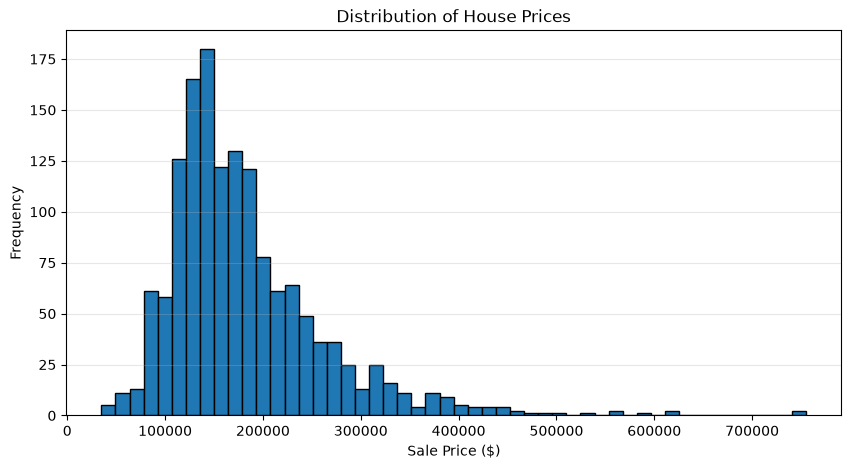

'\nGiải thích:\ndf["SalePrice"]: Truy cập cột giá nhà.\ndescribe(): Thống kê mô tả giá nhà.\nplt.figure(): Khởi tạo biểu đồ.\nbins=50: Chia dữ liệu thành 50 khoảng giá.\nplt.hist(): Vẽ biểu đồ tần suất.\nedgecolor: Tạo đường viền giữa các cột.\n'

In [5]:
# Lấy thống kê mô tả của biến mục tiêu SalePrice
print("SalePrice statistics:")
display(df["SalePrice"].describe())

# Vẽ biểu đồ phân phối giá nhà
plt.figure(figsize=(10, 5))

# Histogram thể hiện tần suất xuất hiện của từng khoảng giá
plt.hist(df["SalePrice"], bins=50, edgecolor="black")

plt.title("Distribution of House Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)

plt.show()

"""
Giải thích:
df["SalePrice"]: Truy cập cột giá nhà.
describe(): Thống kê mô tả giá nhà.
plt.figure(): Khởi tạo biểu đồ.
bins=50: Chia dữ liệu thành 50 khoảng giá.
plt.hist(): Vẽ biểu đồ tần suất.
edgecolor: Tạo đường viền giữa các cột.
"""

In [6]:
# Tính độ lệch của phân phối giá nhà
saleprice_skew = df["SalePrice"].skew()

# Tính độ nhọn của phân phối giá nhà
saleprice_kurt = df["SalePrice"].kurt()

print(f"SalePrice Skewness: {saleprice_skew:.4f}")
print(f"SalePrice Kurtosis: {saleprice_kurt:.4f}")

"""
Giải thích:
skew(): Đo độ lệch của phân phối.
kurt(): Đo độ nhọn (Excess Kurtosis).
Giá trị kurtosis > 0: Phân phối có đuôi nặng hơn phân phối chuẩn.
Giá trị kurtosis < 0: Phân phối có đuôi nhẹ hơn phân phối chuẩn.
"""

SalePrice Skewness: 1.8829
SalePrice Kurtosis: 6.5363


'\nGiải thích:\nskew(): Đo độ lệch của phân phối.\nkurt(): Đo độ nhọn (Excess Kurtosis).\nGiá trị kurtosis > 0: Phân phối có đuôi nặng hơn phân phối chuẩn.\nGiá trị kurtosis < 0: Phân phối có đuôi nhẹ hơn phân phối chuẩn.\n'

Original Skewness: 1.8829
Log Skewness: 0.1213

Original Kurtosis: 6.5363
Log Kurtosis: 0.8095


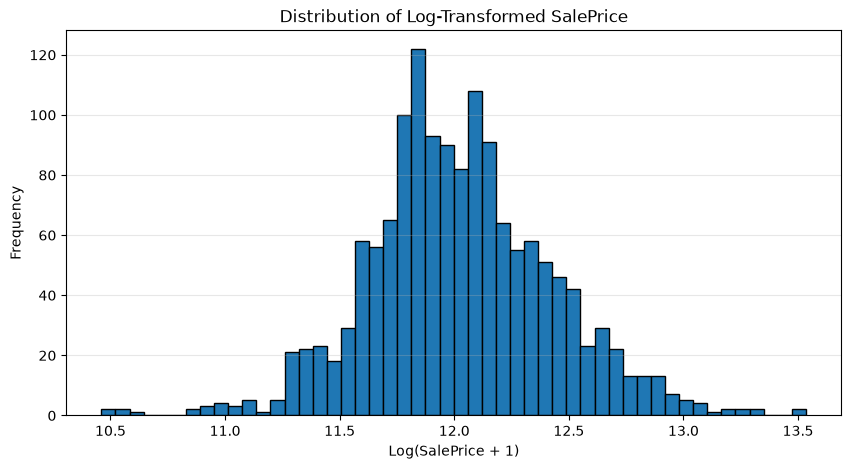

'\nGiải thích:\nnp.log1p(): Tính log(1 + x).\nTạo cột mới thay vì ghi đè SalePrice để giữ dữ liệu gốc.\nskew(): Kiểm tra độ lệch sau biến đổi.\nkurt(): Kiểm tra độ nhọn sau biến đổi.\n'

In [7]:
# Tạo Target mới bằng Log Transformation
df["SalePrice_Log"] = np.log1p(df["SalePrice"])

# Tính lại Skewness sau khi biến đổi
log_skew = df["SalePrice_Log"].skew()

# Tính lại Kurtosis sau khi biến đổi
log_kurt = df["SalePrice_Log"].kurt()

print(f"Original Skewness: {df['SalePrice'].skew():.4f}")
print(f"Log Skewness: {log_skew:.4f}")

print(f"\nOriginal Kurtosis: {df['SalePrice'].kurt():.4f}")
print(f"Log Kurtosis: {log_kurt:.4f}")

# Vẽ phân phối Target sau Log Transformation
plt.figure(figsize=(10, 5))

plt.hist(df["SalePrice_Log"], bins=50, edgecolor="black")

plt.title("Distribution of Log-Transformed SalePrice")
plt.xlabel("Log(SalePrice + 1)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)

plt.show()

"""
Giải thích:
np.log1p(): Tính log(1 + x).
Tạo cột mới thay vì ghi đè SalePrice để giữ dữ liệu gốc.
skew(): Kiểm tra độ lệch sau biến đổi.
kurt(): Kiểm tra độ nhọn sau biến đổi.
"""

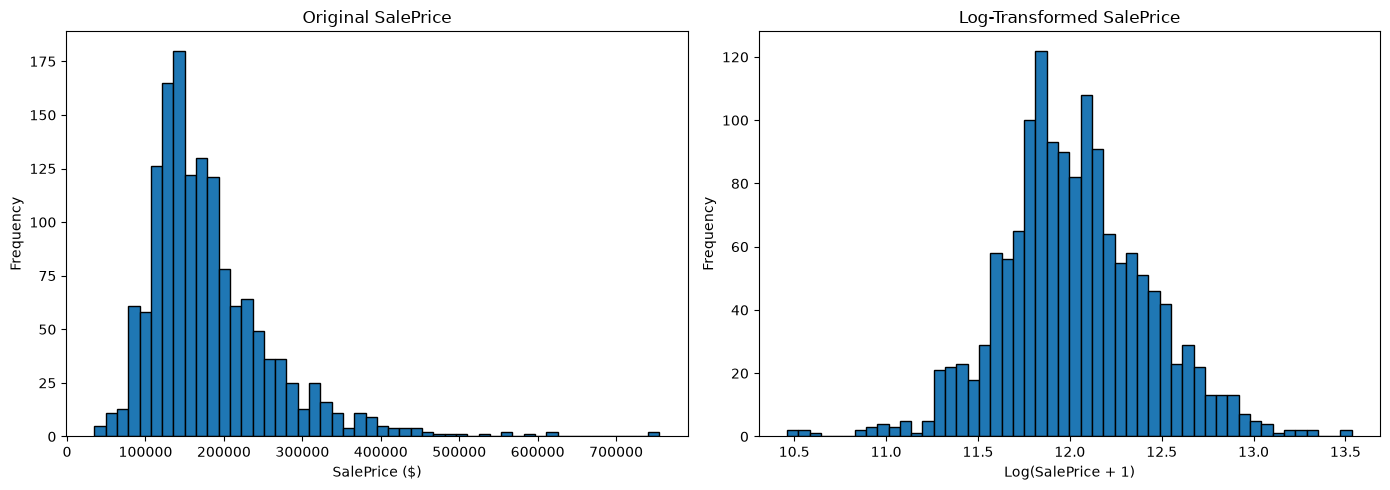

'\nGiải thích:\nplt.subplots(1, 2): Tạo 1 hàng và 2 cột biểu đồ.\naxes[0]: Biểu đồ thứ nhất.\naxes[1]: Biểu đồ thứ hai.\ntight_layout(): Tự động điều chỉnh khoảng cách.\n'

In [8]:
# Tạo figure gồm 2 biểu đồ đặt cạnh nhau
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Phân phối SalePrice gốc
axes[0].hist(df["SalePrice"], bins=50, edgecolor="black")
axes[0].set_title("Original SalePrice")
axes[0].set_xlabel("SalePrice ($)")
axes[0].set_ylabel("Frequency")

# Phân phối SalePrice sau Log Transformation
axes[1].hist(df["SalePrice_Log"], bins=50, edgecolor="black")
axes[1].set_title("Log-Transformed SalePrice")
axes[1].set_xlabel("Log(SalePrice + 1)")
axes[1].set_ylabel("Frequency")

# Điều chỉnh khoảng cách giữa các biểu đồ
plt.tight_layout()

plt.show()

"""
Giải thích:
plt.subplots(1, 2): Tạo 1 hàng và 2 cột biểu đồ.
axes[0]: Biểu đồ thứ nhất.
axes[1]: Biểu đồ thứ hai.
tight_layout(): Tự động điều chỉnh khoảng cách.
"""

In [9]:
# Lấy các feature dạng số trong dataset
numeric_df = df.select_dtypes(include=["int64", "float64"])

# Tính ma trận tương quan giữa các feature dạng số
correlation_matrix = numeric_df.corr()

# Lấy mức tương quan của từng feature với SalePrice
saleprice_corr = correlation_matrix["SalePrice"].sort_values(
    ascending=False
)

# Hiển thị 15 feature có tương quan dương cao nhất
print("Top 15 features positively correlated with SalePrice:")
display(saleprice_corr.head(15))

# Hiển thị 15 feature có tương quan âm mạnh nhất
print("\nTop 15 features negatively correlated with SalePrice:")
display(saleprice_corr.tail(15))

"""
Giải thích:
select_dtypes(): Chọn các cột theo kiểu dữ liệu.
corr(): Tính hệ số tương quan Pearson mặc định.
sort_values(): Sắp xếp theo mức tương quan.
head(15): Lấy 15 feature đầu.
tail(15): Lấy 15 feature cuối.
"""

Top 15 features positively correlated with SalePrice:


SalePrice        1.000000
SalePrice_Log    0.948374
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
Name: SalePrice, dtype: float64


Top 15 features negatively correlated with SalePrice:


BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePrice, dtype: float64

'\nGiải thích:\nselect_dtypes(): Chọn các cột theo kiểu dữ liệu.\ncorr(): Tính hệ số tương quan Pearson mặc định.\nsort_values(): Sắp xếp theo mức tương quan.\nhead(15): Lấy 15 feature đầu.\ntail(15): Lấy 15 feature cuối.\n'

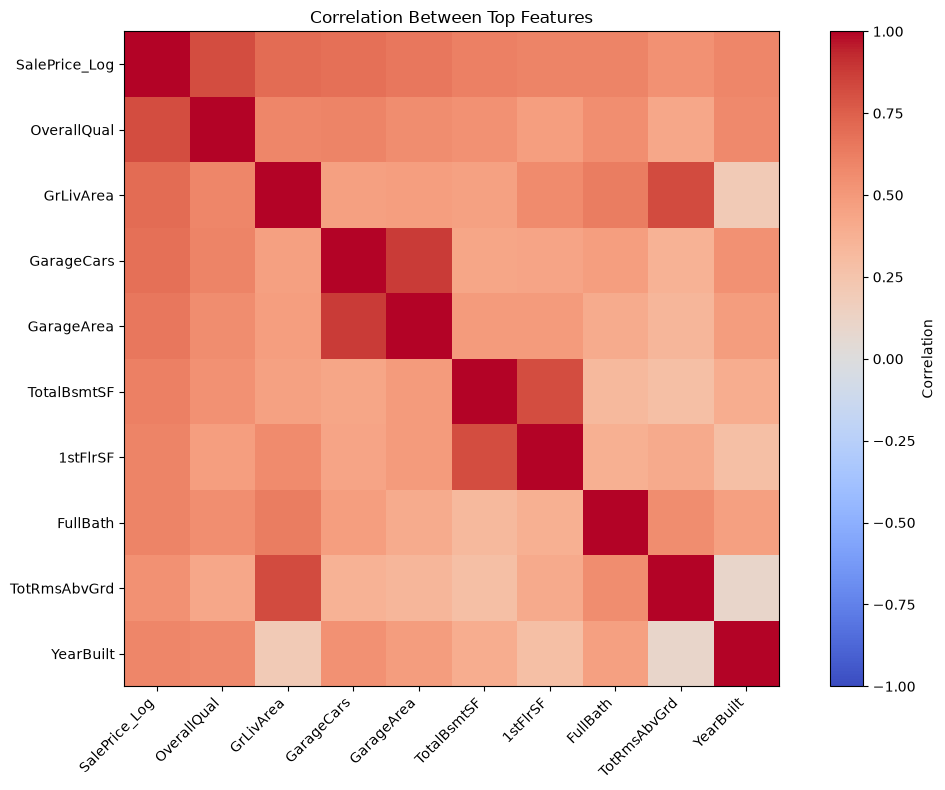

In [10]:
# Chọn 10 feature có tương quan mạnh với SalePrice
top_features = saleprice_corr.abs().sort_values(
    ascending=False
).index[1:11]

# Tạo ma trận tương quan giữa các feature được chọn
feature_corr = numeric_df[top_features].corr()

# Vẽ heatmap bằng Matplotlib
plt.figure(figsize=(11, 8))

plt.imshow(feature_corr, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(top_features)),
    top_features,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(top_features)),
    top_features
)

plt.title("Correlation Between Top Features")
plt.tight_layout()
plt.show()

In [11]:
# Hiển thị ma trận tương quan dạng số
display(feature_corr.round(2))

,SalePrice_Log,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,FullBath,TotRmsAbvGrd,YearBuilt
SalePrice_Log,1.00,0.82,0.70,0.68,0.65,0.61,0.60,0.59,0.53,0.59
OverallQual,0.82,1.00,0.59,0.60,0.56,0.54,0.48,0.55,0.43,0.57
GrLivArea,0.70,0.59,1.00,0.47,0.47,0.45,0.57,0.63,0.83,0.20
GarageCars,0.68,0.60,0.47,1.00,0.88,0.43,0.44,0.47,0.36,0.54
GarageArea,0.65,0.56,0.47,0.88,1.00,0.49,0.49,0.41,0.34,0.48
TotalBsmtSF,0.61,0.54,0.45,0.43,0.49,1.00,0.82,0.32,0.29,0.39
1stFlrSF,0.60,0.48,0.57,0.44,0.49,0.82,1.00,0.38,0.41,0.28
FullBath,0.59,0.55,0.63,0.47,0.41,0.32,0.38,1.00,0.55,0.47
TotRmsAbvGrd,0.53,0.43,0.83,0.36,0.34,0.29,0.41,0.55,1.00,0.10
YearBuilt,0.59,0.57,0.20,0.54,0.48,0.39,0.28,0.47,0.10,1.00


In [14]:
# Hiển thị các biến đang tồn tại
%whos

Variable                    Type         Data/Info
--------------------------------------------------
GridSearchCV                ABCMeta      <class 'sklearn.model_sel<...>on._search.GridSearchCV'>
KFold                       ABCMeta      <class 'sklearn.model_selection._split.KFold'>
KNeighborsRegressor         ABCMeta      <class 'sklearn.neighbors<...>ion.KNeighborsRegressor'>
Pipeline                    ABCMeta      <class 'sklearn.pipeline.Pipeline'>
SimpleImputer               type         <class 'sklearn.impute._base.SimpleImputer'>
StandardScaler              type         <class 'sklearn.preproces<...>ng._data.StandardScaler'>
axes                        ndarray      2: 2 elems, type `object`, 16 bytes
correlation_matrix          DataFrame    Shape: (39, 39)
cross_val_score             function     <function cross_val_score at 0x0000013254A58B80>
df                          DataFrame    Shape: (1460, 82)
feature_corr                DataFrame    Shape: (10, 10)
fig             

In [15]:
# Lấy các feature đã chọn, loại bỏ biến mục tiêu
vif_features = top_features.drop('SalePrice_Log')

# Tạo DataFrame chứa các feature đầu vào
X_vif = df[vif_features].copy()

# Thêm intercept
X_vif = sm.add_constant(X_vif)

print("Số lượng features:", len(vif_features))
print("Shape:", X_vif.shape)

display(X_vif.head())
"""
top_features: Danh sách 10 biến đã chọn.
drop('SalePrice_Log'): Loại target, chỉ giữ 9 biến đầu vào.
df[vif_features]: Lấy dữ liệu tương ứng từ dataset gốc.
sm.add_constant(): Thêm intercept phục vụ tính VIF.
"""

Số lượng features: 9
Shape: (1460, 10)


,const,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,FullBath,TotRmsAbvGrd,YearBuilt
0,1.0,7,1710,2,548,856,856,2,8,2003
1,1.0,6,1262,2,460,1262,1262,2,6,1976
2,1.0,7,1786,2,608,920,920,2,6,2001
3,1.0,7,1717,3,642,756,961,1,7,1915
4,1.0,8,2198,3,836,1145,1145,2,9,2000


"\ntop_features: Danh sách 10 biến đã chọn.\ndrop('SalePrice_Log'): Loại target, chỉ giữ 9 biến đầu vào.\ndf[vif_features]: Lấy dữ liệu tương ứng từ dataset gốc.\nsm.add_constant(): Thêm intercept phục vụ tính VIF.\n"

In [16]:
# Tính VIF cho từng feature
vif_data = pd.DataFrame()

vif_data["Feature"] = X_vif.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# Không cần đánh giá VIF của intercept
vif_data = vif_data[vif_data["Feature"] != "const"]

# Sắp xếp từ VIF cao xuống thấp
vif_data = vif_data.sort_values(
    by="VIF",
    ascending=False
)

display(vif_data.round(2))

,Feature,VIF
3,GarageCars,5.25
2,GrLivArea,5.02
4,GarageArea,4.93
6,1stFlrSF,3.68
5,TotalBsmtSF,3.60
8,TotRmsAbvGrd,3.35
1,OverallQual,2.59
7,FullBath,2.19
9,YearBuilt,2.09


In [17]:
# X: Các biến đầu vào (9 features đã lựa chọn)
X = df[vif_features].copy()

# y: Biến mục tiêu cần dự đoán
y = df["SalePrice_Log"].copy()

# Kiểm tra dữ liệu
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nMissing values trong X:")
display(X.isnull().sum().sort_values(ascending=False))

print("\nTarget:")
print(y.describe())
"""
X: Chứa 9 đặc trưng của căn nhà.
y: Chứa giá nhà đã Log Transformation.
.copy(): Tạo bản sao để tránh chỉnh sửa trực tiếp dữ liệu gốc.
isnull().sum(): Đếm số lượng giá trị thiếu trong từng feature
describe(): Thống kê phân phối của target.
"""

X shape: (1460, 9)
y shape: (1460,)

Missing values trong X:


OverallQual     0
GrLivArea       0
GarageCars      0
GarageArea      0
TotalBsmtSF     0
1stFlrSF        0
FullBath        0
TotRmsAbvGrd    0
YearBuilt       0
dtype: int64


Target:
count    1460.000000
mean       12.024057
std         0.399449
min        10.460271
25%        11.775105
50%        12.001512
75%        12.273736
max        13.534474
Name: SalePrice_Log, dtype: float64


'\nX: Chứa 9 đặc trưng của căn nhà.\ny: Chứa giá nhà đã Log Transformation.\n.copy(): Tạo bản sao để tránh chỉnh sửa trực tiếp dữ liệu gốc.\nisnull().sum(): Đếm số lượng giá trị thiếu trong từng feature\ndescribe(): Thống kê phân phối của target.\n'

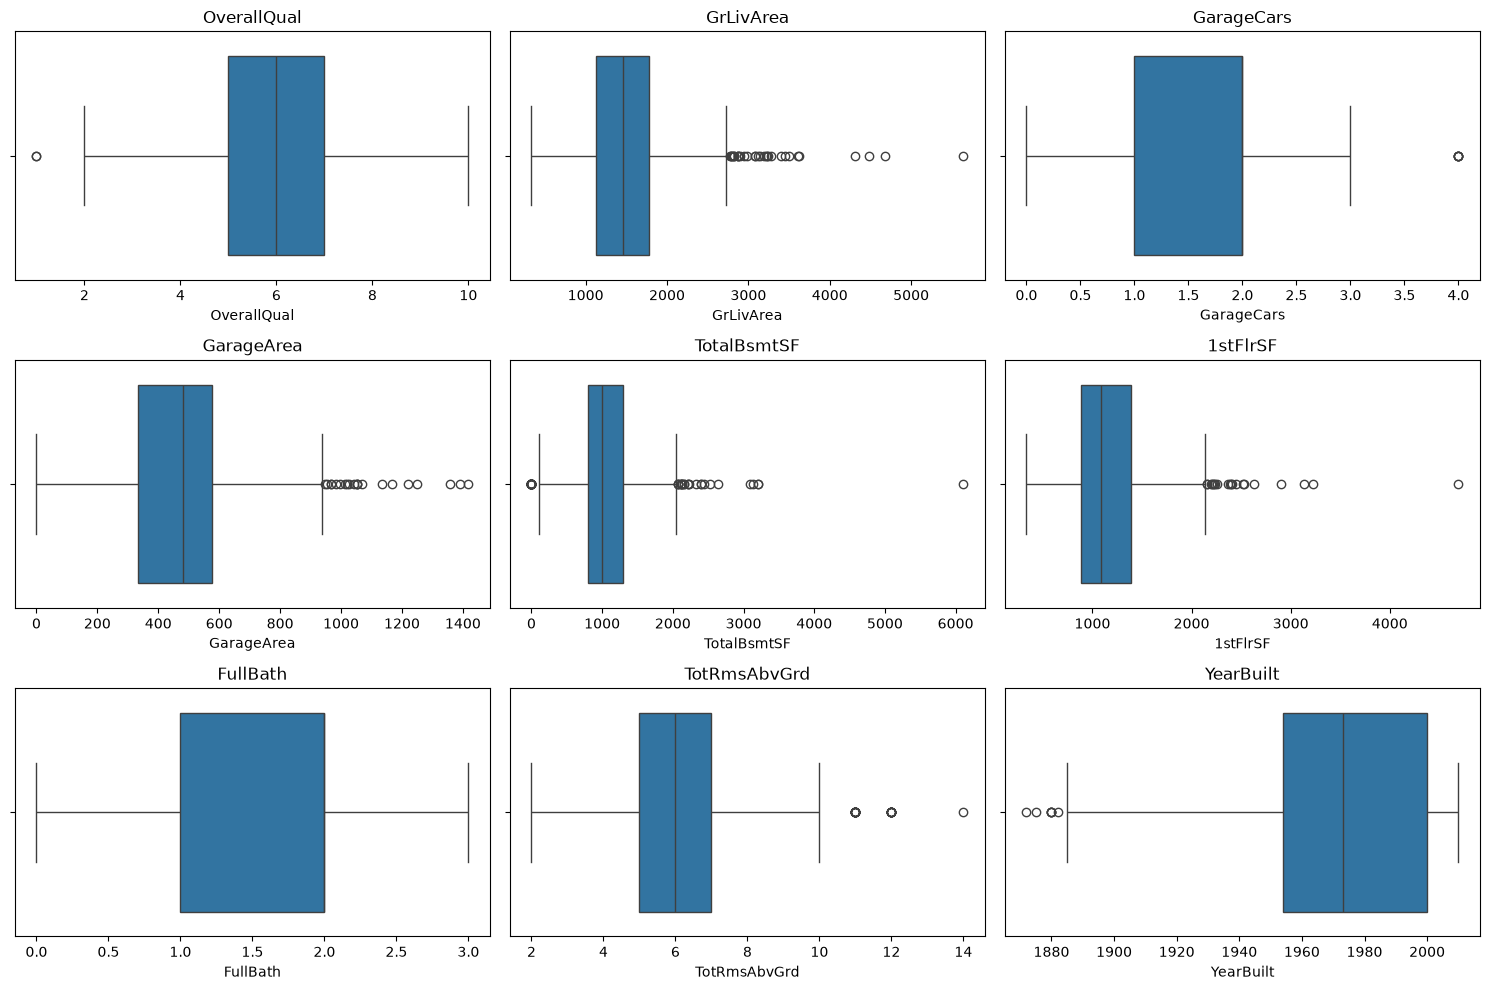

'\nplt.subplots(3, 3): Tạo 9 biểu đồ.\nX.columns: Duyệt qua từng feature.\nsns.boxplot(): Hiển thị Median, Q1, Q3 và các điểm ngoại lệ theo quy tắc IQR.\n'

In [18]:
# Vẽ Boxplot cho 9 features
fig, axes = plt.subplots(3, 3, figsize=(15, 10))

for ax, col in zip(axes.flatten(), X.columns):
    sns.boxplot(x=X[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()
"""
plt.subplots(3, 3): Tạo 9 biểu đồ.
X.columns: Duyệt qua từng feature.
sns.boxplot(): Hiển thị Median, Q1, Q3 và các điểm ngoại lệ theo quy tắc IQR.
"""

In [19]:
# Tạo bảng thống kê Outliers
outlier_data = []

for col in X.columns:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Xác định các giá trị ngoại lệ
    outliers = X[
        (X[col] < lower_bound) |
        (X[col] > upper_bound)
    ][col]

    outlier_data.append({
        "Feature": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier (%)": len(outliers) / len(X) * 100
    })

outlier_summary = pd.DataFrame(outlier_data)

display(outlier_summary.round(2))
"""
Mục đích
Thay vì nhìn biểu đồ, ta có thể biết chính xác:
- Feature nào có outlier.
- Có bao nhiêu outlier.
- Tỷ lệ outlier trên tổng dữ liệu.
- Ngưỡng nào được dùng để xác định outlier.
"""

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier (%)
0,OverallQual,2.00,10.00,2,0.14
1,GrLivArea,158.62,2747.62,31,2.12
2,GarageCars,-0.50,3.50,5,0.34
3,GarageArea,-27.75,938.25,21,1.44
4,TotalBsmtSF,42.00,2052.00,61,4.18
5,1stFlrSF,118.12,2155.12,20,1.37
6,FullBath,-0.50,3.50,0,0.00
7,TotRmsAbvGrd,2.00,10.00,30,2.05
8,YearBuilt,1885.00,2069.00,7,0.48


'\nMục đích\nThay vì nhìn biểu đồ, ta có thể biết chính xác:\n- Feature nào có outlier.\n- Có bao nhiêu outlier.\n- Tỷ lệ outlier trên tổng dữ liệu.\n- Ngưỡng nào được dùng để xác định outlier.\n'

In [20]:
# Tính Skewness cho từng feature
skewness = X.skew().sort_values(ascending=False)

skewness_summary = pd.DataFrame({
    "Feature": skewness.index,
    "Skewness": skewness.values
})

display(skewness_summary.round(3))
"""
Skewness đo mức độ bất đối xứng của phân phối.
Skewness > 0: Lệch phải.
Skewness < 0: Lệch trái.
Skewness gần 0: Tương đối đối xứng.
"""

,Feature,Skewness
0,TotalBsmtSF,1.524
1,1stFlrSF,1.377
2,GrLivArea,1.367
3,TotRmsAbvGrd,0.676
4,OverallQual,0.217
5,GarageArea,0.180
6,FullBath,0.037
7,GarageCars,-0.343
8,YearBuilt,-0.613


'\nSkewness đo mức độ bất đối xứng của phân phối.\nSkewness > 0: Lệch phải.\nSkewness < 0: Lệch trái.\nSkewness gần 0: Tương đối đối xứng.\n'

In [21]:
# Chọn 3 feature có độ lệch phải mạnh
log_features = [
    "TotalBsmtSF",
    "1stFlrSF",
    "GrLivArea"
]

# Tạo bản sao để thử nghiệm, không thay đổi X gốc
X_log_test = X[log_features].copy()

# Áp dụng Log Transformation
for col in log_features:
    X_log_test[col] = np.log1p(X_log_test[col])

# So sánh Skewness trước và sau biến đổi
skew_comparison = pd.DataFrame({
    "Before": X[log_features].skew(),
    "After": X_log_test.skew()
})

display(skew_comparison.round(3))
"""
Giải thích
- np.log1p(x): Tính ln(1+x).
- Dùng log1p thay vì log để xử lý được cả giá trị bằng 0.
- X_log_test: Bản thử nghiệm, không làm thay đổi dữ liệu gốc.
- So sánh Skewness để xem Log Transformation có thực sự cải thiện phân phối không.
"""

,Before,After
TotalBsmtSF,1.524,-5.155
1stFlrSF,1.377,0.080
GrLivArea,1.367,-0.006


'\nGiải thích\n- np.log1p(x): Tính ln(1+x).\n- Dùng log1p thay vì log để xử lý được cả giá trị bằng 0.\n- X_log_test: Bản thử nghiệm, không làm thay đổi dữ liệu gốc.\n- So sánh Skewness để xem Log Transformation có thực sự cải thiện phân phối không.\n'

In [22]:
# Kiểm tra số lượng và tỷ lệ giá trị bằng 0
zero_analysis = pd.DataFrame({
    "Zero Count": (X == 0).sum(),
    "Zero Percentage": (X == 0).mean() * 100
})

display(zero_analysis.round(2))

# Kiểm tra riêng TotalBsmtSF nếu chỉ xét nhà có tầng hầm
basement_positive = X.loc[X["TotalBsmtSF"] > 0, "TotalBsmtSF"]

print("TotalBsmtSF > 0:", len(basement_positive))
print("Skewness khi loại các giá trị 0:", basement_positive.skew().round(3))
"""
Mục đích
Chúng ta muốn xác định:
- Có bao nhiêu căn nhà không có tầng hầm?
- Tỷ lệ chiếm bao nhiêu phần trăm?
- Nếu chỉ xét nhà có tầng hầm, phân phối có còn lệch phải không?
"""

,Zero Count,Zero Percentage
OverallQual,0,0.00
GrLivArea,0,0.00
GarageCars,81,5.55
GarageArea,81,5.55
TotalBsmtSF,37,2.53
1stFlrSF,0,0.00
FullBath,9,0.62
TotRmsAbvGrd,0,0.00
YearBuilt,0,0.00


TotalBsmtSF > 0: 1423
Skewness khi loại các giá trị 0: 2.171


'\nMục đích\nChúng ta muốn xác định:\n- Có bao nhiêu căn nhà không có tầng hầm?\n- Tỷ lệ chiếm bao nhiêu phần trăm?\n- Nếu chỉ xét nhà có tầng hầm, phân phối có còn lệch phải không?\n'

In [23]:
# Lấy những căn nhà có tầng hầm
basement_positive = X.loc[
    X["TotalBsmtSF"] > 0, "TotalBsmtSF"
]

# So sánh phân phối trước và sau Log Transformation
basement_analysis = pd.DataFrame({
    "Original": basement_positive.describe(),
    "Log_Transformed": np.log1p(basement_positive).describe()
})

display(basement_analysis.round(3))

print("Original Skewness:", basement_positive.skew().round(3))
print("Log Skewness:", np.log1p(basement_positive).skew().round(3))
"""
Mục đích:
Ta tách riêng 1,423 căn nhà có tầng hầm để xem Log Transformation thực sự có tác dụng thế nào khi không có nhóm giá trị 0.
"""

,Original,Log_Transformed
count,1423.000,1423.000
mean,1084.924,6.926
std,409.414,0.361
min,105.000,4.663
25%,810.500,6.699
50%,1004.000,6.913
75%,1309.500,7.178
max,6110.000,8.718


Original Skewness: 2.171
Log Skewness: -0.273


'\nMục đích:\nTa tách riêng 1,423 căn nhà có tầng hầm để xem Log Transformation thực sự có tác dụng thế nào khi không có nhóm giá trị 0.\n'

In [24]:
from sklearn.model_selection import train_test_split

# Chia dữ liệu thành tập train (80%) và test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Kiểm tra kích thước sau khi chia
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
"""
test_size=0.2: Dành 20% dữ liệu để đánh giá model.
random_state=42: Đảm bảo mỗi lần chạy đều chia dữ liệu giống nhau.
X_train, y_train: Dữ liệu dùng để học.
X_test, y_test: Dữ liệu giữ riêng để đánh giá khả năng dự đoán.
"""

X_train: (1168, 9)
X_test: (292, 9)
y_train: (1168,)
y_test: (292,)


'\ntest_size=0.2: Dành 20% dữ liệu để đánh giá model.\nrandom_state=42: Đảm bảo mỗi lần chạy đều chia dữ liệu giống nhau.\nX_train, y_train: Dữ liệu dùng để học.\nX_test, y_test: Dữ liệu giữ riêng để đánh giá khả năng dự đoán.\n'

In [25]:

import numpy as np

# Tạo bản sao để giữ nguyên dữ liệu gốc
X_train_log = X_train.copy()
X_test_log = X_test.copy()

# Log transformation cho hai features trên tập train
X_train_log["GrLivArea"] = np.log1p(X_train_log["GrLivArea"])
X_train_log["1stFlrSF"] = np.log1p(X_train_log["1stFlrSF"])

# Áp dụng cùng phép biến đổi lên tập test
X_test_log["GrLivArea"] = np.log1p(X_test_log["GrLivArea"])
X_test_log["1stFlrSF"] = np.log1p(X_test_log["1stFlrSF"])

# Kiểm tra kết quả
X_train_log[["GrLivArea", "1stFlrSF"]].describe()
"""
Giải thích
- np.log1p(x) tương đương log(1+x).
- Dùng log1p thay vì log để xử lý được cả giá trị bằng 0.
- .copy() giúp giữ dữ liệu gốc để có thể so sánh trước và sau transformation.
- Log Transformation không học tham số từ dữ liệu nên có thể áp dụng trực tiếp lên train và test.
"""

'\nGiải thích\n- np.log1p(x) tương đương log(1+x).\n- Dùng log1p thay vì log để xử lý được cả giá trị bằng 0.\n- .copy() giúp giữ dữ liệu gốc để có thể so sánh trước và sau transformation.\n- Log Transformation không học tham số từ dữ liệu nên có thể áp dụng trực tiếp lên train và test.\n'

In [26]:

# Tính độ lệch của phân phối trước và sau Log Transformation
skew_comparison = pd.DataFrame({
    "Original": X_train[["GrLivArea", "1stFlrSF"]].skew(),
    "Log_Transformed": X_train_log[["GrLivArea", "1stFlrSF"]].skew()
})

skew_comparison


,Original,Log_Transformed
GrLivArea,1.425139,0.007943
1stFlrSF,1.422162,0.026976


In [27]:

from sklearn.preprocessing import StandardScaler

# Khởi tạo scaler
scaler = StandardScaler()

# Fit và transform trên tập train
X_train_scaled = scaler.fit_transform(X_train_log)

# Chỉ transform trên tập test
X_test_scaled = scaler.transform(X_test_log)

# Kiểm tra kết quả Scaling
print("Train mean:", X_train_scaled.mean(axis=0).round(3))
print("Train std:", X_train_scaled.std(axis=0).round(3))

print("Train shape:", X_train_scaled.shape)
print("Test shape:", X_test_scaled.shape)
"""
Giải thích
1. StandardScaler
Công thức:
z = x-mu/sigma
Trong đó:
- x: Giá trị ban đầu.
- mu: Mean của feature trên tập train.
- sigma: Standard deviation của feature trên tập train.
- z: Giá trị sau Scaling.
2. Tại sao phải fit trên train?
- fit_transform(): Học mean và std từ train, sau đó biến đổi train.
- transform(): Dùng chính mean và std đã học để biến đổi test.
Nếu fit riêng trên test, model sẽ vô tình sử dụng thông tin thống kê từ tập kiểm thử → Data Leakage.
"""

Train mean: [-0.  0.  0.  0.  0.  0. -0. -0. -0.]
Train std: [1. 1. 1. 1. 1. 1. 1. 1. 1.]
Train shape: (1168, 9)
Test shape: (292, 9)


'\nGiải thích\n1. StandardScaler\nCông thức:\nz = x-mu/sigma\nTrong đó:\n- x: Giá trị ban đầu.\n- mu: Mean của feature trên tập train.\n- sigma: Standard deviation của feature trên tập train.\n- z: Giá trị sau Scaling.\n2. Tại sao phải fit trên train?\n- fit_transform(): Học mean và std từ train, sau đó biến đổi train.\n- transform(): Dùng chính mean và std đã học để biến đổi test.\nNếu fit riêng trên test, model sẽ vô tình sử dụng thông tin thống kê từ tập kiểm thử → Data Leakage.\n'

In [28]:

from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Khởi tạo KNN Regression chọn k=5 vì phổ biến
knn = KNeighborsRegressor(n_neighbors=5)

# Huấn luyện model trên dữ liệu đã Scaling
knn.fit(X_train_scaled, y_train)

# Dự đoán trên tập test
y_pred = knn.predict(X_test_scaled)

# Đánh giá model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2:   {r2:.4f}")
"""
Giải thích
1. KNeighborsRegressor
KNN Regression dự đoán giá nhà bằng cách tìm K căn nhà gần nhất với căn nhà cần dự đoán, sau đó lấy trung bình giá trị target của chúng.
2. fit()
Model lưu dữ liệu huấn luyện để phục vụ việc tìm kiếm hàng xóm gần nhất.
Khác Linear Regression, KNN không học một phương trình tuyến tính gồm các hệ số trọng số.
3. Ba chỉ số đánh giá
Metric	Ý nghĩa	Tốt khi
MAE	Sai số tuyệt đối trung bình	Càng thấp
RMSE	Sai số bình phương trung bình rồi lấy căn	Càng thấp
R²	Mức độ giải thích biến thiên của target	Càng gần 1
Lưu ý quan trọng: Target của m là SalePrice_Log, nên MAE và RMSE hiện tại đang ở thang log, chưa phải USD.
"""

MAE:  0.1284
RMSE: 0.1907
R2:   0.8050


'\nGiải thích\n1. KNeighborsRegressor\nKNN Regression dự đoán giá nhà bằng cách tìm K căn nhà gần nhất với căn nhà cần dự đoán, sau đó lấy trung bình giá trị target của chúng.\n2. fit()\nModel lưu dữ liệu huấn luyện để phục vụ việc tìm kiếm hàng xóm gần nhất.\nKhác Linear Regression, KNN không học một phương trình tuyến tính gồm các hệ số trọng số.\n3. Ba chỉ số đánh giá\nMetric\tÝ nghĩa\tTốt khi\nMAE\tSai số tuyệt đối trung bình\tCàng thấp\nRMSE\tSai số bình phương trung bình rồi lấy căn\tCàng thấp\nR²\tMức độ giải thích biến thiên của target\tCàng gần 1\nLưu ý quan trọng: Target của m là SalePrice_Log, nên MAE và RMSE hiện tại đang ở thang log, chưa phải USD.\n'

In [29]:

# Dự đoán trên Train và Test
y_train_pred = knn.predict(X_train_scaled)
y_test_pred = knn.predict(X_test_scaled)

# Tạo bảng đánh giá hai tập dữ liệu
evaluation = pd.DataFrame({
    "Train": [
        mean_absolute_error(y_train, y_train_pred),
        np.sqrt(mean_squared_error(y_train, y_train_pred)),
        r2_score(y_train, y_train_pred)
    ],
    "Test": [
        mean_absolute_error(y_test, y_test_pred),
        np.sqrt(mean_squared_error(y_test, y_test_pred)),
        r2_score(y_test, y_test_pred)
    ]
}, index=["MAE", "RMSE", "R2"])

evaluation
"""
Trường hợp	Train	Test
Overfitting	Rất tốt	Kém hơn rõ rệt
Underfitting	Kém	Cũng kém
Generalization tốt	Tốt	Gần tương đương

Đây là dấu hiệu chẩn đoán, không phải quy tắc tuyệt đối. Cần xét thêm Cross Validation và độ biến thiên giữa các fold.

KNN Regression – K = 5
Metric	Train	Test
MAE	0.1004	0.1284
RMSE	0.1399	0.1907
R²	0.8715	0.8050

Nhận xét:
- Test MAE và RMSE cao hơn Train.
- Test R² thấp hơn Train.
- R² gap = 0.0665.
- Có generalization gap, cần kiểm tra thêm bằng Cross Validation.
"""


'\nTrường hợp\tTrain\tTest\nOverfitting\tRất tốt\tKém hơn rõ rệt\nUnderfitting\tKém\tCũng kém\nGeneralization tốt\tTốt\tGần tương đương\n\nĐây là dấu hiệu chẩn đoán, không phải quy tắc tuyệt đối. Cần xét thêm Cross Validation và độ biến thiên giữa các fold.\n\nKNN Regression – K = 5\nMetric\tTrain\tTest\nMAE\t0.1004\t0.1284\nRMSE\t0.1399\t0.1907\nR²\t0.8715\t0.8050\n\nNhận xét:\n- Test MAE và RMSE cao hơn Train.\n- Test R² thấp hơn Train.\n- R² gap = 0.0665.\n- Có generalization gap, cần kiểm tra thêm bằng Cross Validation.\n'

In [33]:

from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline

# Chia tập train thành 5 folds
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Thử các giá trị K từ 1 đến 30
k_values = range(1, 31)

results = []

for k in k_values:

    # Pipeline: Scaling → KNN
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsRegressor(n_neighbors=k))
    ])

    # Đánh giá bằng 5-Fold Cross Validation
    scores = cross_val_score(
        model,
        X_train_log,
        y_train,
        cv=kf,
        scoring="neg_root_mean_squared_error"
    )

    # Lưu RMSE trung bình và độ lệch chuẩn
    results.append({
        "n_neighbors": k,
        "CV_RMSE_Mean": -scores.mean(),
        "CV_RMSE_Std": scores.std()
    })

# Sắp xếp theo RMSE trung bình tăng dần
cv_results_sorted = cv_results.sort_values(
    by="CV_RMSE_Mean",
    ascending=True
)
"""
sort_values(): Sắp xếp các giá trị.
ascending=True: RMSE thấp nhất đứng đầu.
head(10): Lấy 10 dòng đầu tiên.
display(): Hiển thị DataFrame trong Jupyter.
to_string(index=False): In bảng dạng văn bản, không có index.
"""

# Hiển thị 10 cấu hình tốt nhất

# Hiển thị lại kết quả với định dạng rõ ràng
display(
    cv_results_sorted.head(10).style.format({
        "CV_RMSE_Mean": "{:.6f}",
        "CV_RMSE_Std": "{:.6f}"
    })
)

"""
1. K-Fold Cross Validation

Với 5 folds, dữ liệu được chia thành 5 phần:
Mỗi lần:
- 4 phần dùng để train.
- 1 phần dùng để validation.
- Lặp lại 5 lần để mỗi phần đều được validation một lần.
2. cross_val_score()
Thực hiện huấn luyện và đánh giá model qua các folds.
3. neg_root_mean_squared_error
Scikit-learn sử dụng quy ước điểm số càng cao càng tốt nên RMSE được trả về dưới dạng số âm. Ta dùng -scores.mean() để đưa về RMSE thông thường.
4. CV_RMSE_Std
Độ lệch chuẩn RMSE giữa các folds. Càng thấp thường cho thấy model ổn định hơn giữa các tập validation.
"""

,n_neighbors,CV_RMSE_Mean,CV_RMSE_Std
6,7,0.172181,0.013644
11,12,0.172184,0.013748
10,11,0.172272,0.013123
12,13,0.172309,0.014047
7,8,0.172488,0.012722
9,10,0.172536,0.012309
5,6,0.172581,0.014995
13,14,0.172814,0.013633
14,15,0.172978,0.013456
8,9,0.173320,0.012530


'\n1. K-Fold Cross Validation\n\nVới 5 folds, dữ liệu được chia thành 5 phần:\nMỗi lần:\n- 4 phần dùng để train.\n- 1 phần dùng để validation.\n- Lặp lại 5 lần để mỗi phần đều được validation một lần.\n2. cross_val_score()\nThực hiện huấn luyện và đánh giá model qua các folds.\n3. neg_root_mean_squared_error\nScikit-learn sử dụng quy ước điểm số càng cao càng tốt nên RMSE được trả về dưới dạng số âm. Ta dùng -scores.mean() để đưa về RMSE thông thường.\n4. CV_RMSE_Std\nĐộ lệch chuẩn RMSE giữa các folds. Càng thấp thường cho thấy model ổn định hơn giữa các tập validation.\n'

In [30]:

# Kiểm tra các biến dữ liệu hiện đang tồn tại
print("X_train:", "X_train" in globals())
print("X_train_log:", "X_train_log" in globals())
print("X_test_log:", "X_test_log" in globals())
print("y_train:", "y_train" in globals())


X_train: True
X_train_log: True
X_test_log: True
y_train: True


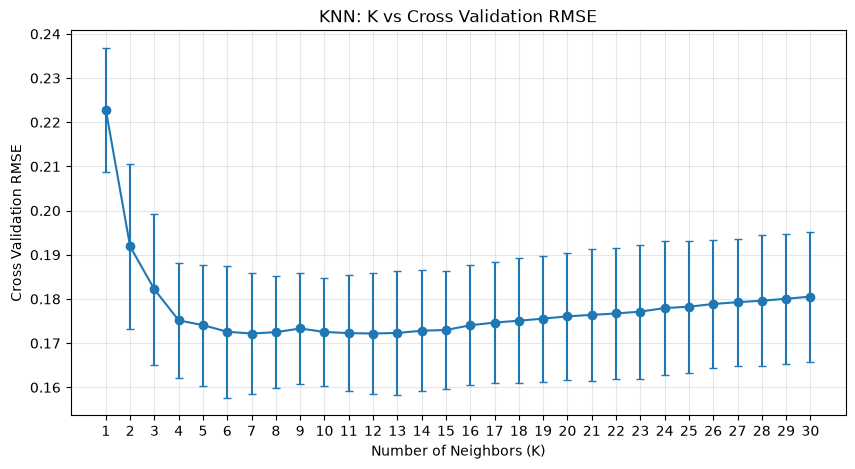

In [34]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.errorbar(
    cv_results["n_neighbors"],
    cv_results["CV_RMSE_Mean"],
    yerr=cv_results["CV_RMSE_Std"],
    marker="o",
    capsize=3
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Cross Validation RMSE")
plt.title("KNN: K vs Cross Validation RMSE")
plt.xticks(range(1, 31))
plt.grid(True, alpha=0.3)

plt.show()
"""
Cách đánh giá:
1. Đường RMSE càng thấp → dự đoán càng tốt.
2. Điểm thấp nhất → cấu hình có RMSE trung bình tốt nhất.
3. Đường giảm rồi tăng → có thể xuất hiện vùng K phù hợp.
4. Đường gần như nằm ngang → các giá trị K có hiệu suất tương đương.
5. Error bar càng ngắn → kết quả giữa các folds càng ít biến động.
Lưu ý: Không phải cứ K càng lớn thì RMSE càng tăng. Quan hệ thực tế phụ thuộc dataset.
"""


In [35]:

# Lấy cấu hình có CV RMSE thấp nhất
best_row = cv_results.loc[cv_results["CV_RMSE_Mean"].idxmin()]

# Lấy cấu hình có độ ổn định tốt nhất
stable_row = cv_results.loc[cv_results["CV_RMSE_Std"].idxmin()]

# Tìm RMSE thấp nhất và cao nhất
min_rmse = cv_results["CV_RMSE_Mean"].min()
max_rmse = cv_results["CV_RMSE_Mean"].max()

print("===== BEST MODEL =====")
print(f"Best K: {int(best_row['n_neighbors'])}")
print(f"Mean RMSE: {best_row['CV_RMSE_Mean']:.6f}")
print(f"Std RMSE: {best_row['CV_RMSE_Std']:.6f}")

print("\n===== MOST STABLE MODEL =====")
print(f"Stable K: {int(stable_row['n_neighbors'])}")
print(f"Std RMSE: {stable_row['CV_RMSE_Std']:.6f}")

print("\n===== RMSE RANGE =====")
print(f"Minimum: {min_rmse:.6f}")
print(f"Maximum: {max_rmse:.6f}")
print(f"Range: {max_rmse - min_rmse:.6f}")

# Những K có RMSE cách mức tốt nhất không quá 1%
near_best = cv_results[
    cv_results["CV_RMSE_Mean"] <= min_rmse * 1.01
]

print("\n===== K WITHIN 1% OF BEST RMSE =====")
print(near_best.to_string(index=False))


===== BEST MODEL =====
Best K: 7
Mean RMSE: 0.172181
Std RMSE: 0.013644

===== MOST STABLE MODEL =====
Stable K: 10
Std RMSE: 0.012309

===== RMSE RANGE =====
Minimum: 0.172181
Maximum: 0.222799
Range: 0.050618

===== K WITHIN 1% OF BEST RMSE =====
 n_neighbors  CV_RMSE_Mean  CV_RMSE_Std
           6      0.172581     0.014995
           7      0.172181     0.013644
           8      0.172488     0.012722
           9      0.173320     0.012530
          10      0.172536     0.012309
          11      0.172272     0.013123
          12      0.172184     0.013748
          13      0.172309     0.014047
          14      0.172814     0.013633
          15      0.172978     0.013456


In [36]:

# Tạo model cuối cùng với K=10
best_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsRegressor(n_neighbors=10))
])

# Huấn luyện trên toàn bộ tập Train
best_knn.fit(X_train_log, y_train)

# Dự đoán trên Train và Test
y_train_pred_final = best_knn.predict(X_train_log)
y_test_pred_final = best_knn.predict(X_test_log)

# Đánh giá model
final_evaluation = pd.DataFrame({
    "Train": [
        mean_absolute_error(y_train, y_train_pred_final),
        np.sqrt(mean_squared_error(y_train, y_train_pred_final)),
        r2_score(y_train, y_train_pred_final)
    ],
    "Test": [
        mean_absolute_error(y_test, y_test_pred_final),
        np.sqrt(mean_squared_error(y_test, y_test_pred_final)),
        r2_score(y_test, y_test_pred_final)
    ]
}, index=["MAE", "RMSE", "R2"])

display(final_evaluation.round(6))
"""
Tại sao lại dùng Pipeline?
Trước đây ta đã Scaling thủ công. Bây giờ Pipeline tự thực hiện:
1. Nhận dữ liệu train.
2. Fit StandardScaler trên train.
3. Transform train.
4. Huấn luyện KNN với K=10.
Khi dự đoán test, Pipeline tự dùng scaler đã fit từ train.
Đây cũng là cách tổ chức preprocessing và model thường dùng trong production.
Lưu ý: Test set bây giờ chỉ dùng để đánh giá cuối cùng, không dùng để tiếp tục lựa chọn K.
"""

,Train,Test
MAE,0.108824,0.121327
RMSE,0.154219,0.183119
R2,0.843984,0.820308


'\nTại sao lại dùng Pipeline?\nTrước đây ta đã Scaling thủ công. Bây giờ Pipeline tự thực hiện:\n1. Nhận dữ liệu train.\n2. Fit StandardScaler trên train.\n3. Transform train.\n4. Huấn luyện KNN với K=10.\nKhi dự đoán test, Pipeline tự dùng scaler đã fit từ train.\nĐây cũng là cách tổ chức preprocessing và model thường dùng trong production.\nLưu ý: Test set bây giờ chỉ dùng để đánh giá cuối cùng, không dùng để tiếp tục lựa chọn K.\n'

In [37]:
# Chuyển giá trị thực tế và dự đoán từ Log về giá USD
y_test_original = np.expm1(y_test)
y_pred_original = np.expm1(y_pred)

# Tính sai số trên thang giá gốc
mae_usd = mean_absolute_error(y_test_original, y_pred_original)
rmse_usd = np.sqrt(mean_squared_error(y_test_original, y_pred_original))

# In kết quả
print("===== KNN REGRESSION - ORIGINAL PRICE =====")
print(f"MAE : ${mae_usd:,.2f}")
print(f"RMSE: ${rmse_usd:,.2f}")
"""
Giải thích
- np.expm1(x): thực hiện phép biến đổi ngược của np.log1p(x).
- y_test_original: giá nhà thực tế tính bằng USD.
- y_pred_original: giá nhà do KNN dự đoán, tính bằng USD.
- MAE: trung bình mỗi dự đoán lệch bao nhiêu USD.
- RMSE: phạt nặng hơn những dự đoán có sai số lớn.
"""

===== KNN REGRESSION - ORIGINAL PRICE =====
MAE : $22,574.75
RMSE: $37,705.48


'\nGiải thích\n- np.expm1(x): thực hiện phép biến đổi ngược của np.log1p(x).\n- y_test_original: giá nhà thực tế tính bằng USD.\n- y_pred_original: giá nhà do KNN dự đoán, tính bằng USD.\n- MAE: trung bình mỗi dự đoán lệch bao nhiêu USD.\n- RMSE: phạt nặng hơn những dự đoán có sai số lớn.\n'

In [38]:
# Tạo bảng so sánh giá thực tế và giá dự đoán
results = pd.DataFrame({
    "Actual_Price": y_test_original,
    "Predicted_Price": y_pred_original
})

# Tính sai số tuyệt đối
results["Absolute_Error"] = abs(
    results["Actual_Price"] - results["Predicted_Price"]
)

# Sắp xếp 10 căn nhà có sai số lớn nhất
worst_predictions = results.sort_values(
    by="Absolute_Error",
    ascending=False
).head(10)

display(worst_predictions)
"""
Mục tiêu của cell này:
1. Quan sát những căn nhà KNN dự đoán sai nhiều nhất.
2. Xem model đang đánh giá thấp hay đánh giá cao giá nhà.
3. Hiểu hạn chế của KNN trong bài toán dự đoán giá nhà.
"""

,Actual_Price,Predicted_Price,Absolute_Error
691,755000.0,454823.568072,300176.431928
898,611657.0,402160.861186,209496.138814
581,253293.0,405769.314066,152476.314066
218,311500.0,172437.446913,139062.553087
451,280000.0,160059.689985,119940.310015
1243,465000.0,350252.545733,114747.454267
332,284000.0,382486.083301,98486.083301
907,250000.0,156153.751845,93846.248155
261,276000.0,362099.943001,86099.943001
231,403000.0,320906.217152,82093.782848


'\nMục tiêu của cell này:\n1. Quan sát những căn nhà KNN dự đoán sai nhiều nhất.\n2. Xem model đang đánh giá thấp hay đánh giá cao giá nhà.\n3. Hiểu hạn chế của KNN trong bài toán dự đoán giá nhà.\n'

In [39]:
# Lấy đặc điểm của 10 căn nhà dự đoán sai nhiều nhất
worst_features = X_test.loc[worst_predictions.index]

# Kết hợp đặc điểm với giá thực tế và giá dự đoán
worst_analysis = pd.concat(
    [worst_features, worst_predictions],
    axis=1
)

display(worst_analysis)

,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,1stFlrSF,FullBath,TotRmsAbvGrd,YearBuilt,Actual_Price,Predicted_Price,Absolute_Error
691,10,4316,3,832,2444,2444,3,10,1994,755000.0,454823.568072,300176.431928
898,9,2364,3,820,2330,2364,2,11,2009,611657.0,402160.861186,209496.138814
581,8,2042,3,1390,2042,2042,2,8,2008,253293.0,405769.314066,152476.314066
218,7,1954,2,431,798,1137,1,8,1939,311500.0,172437.446913,139062.553087
451,7,1533,2,576,1533,1533,2,5,1975,280000.0,160059.689985,119940.310015
1243,10,2076,3,850,2076,2076,2,7,2006,465000.0,350252.545733,114747.454267
332,8,1629,3,880,3206,1629,2,7,2003,284000.0,382486.083301,98486.083301
907,7,2057,1,180,1017,1020,1,6,1936,250000.0,156153.751845,93846.248155
261,8,2574,3,868,1482,1482,2,10,2007,276000.0,362099.943001,86099.943001
231,8,2794,3,810,1462,1490,2,9,1995,403000.0,320906.217152,82093.782848


In [46]:
from sklearn.model_selection import GridSearchCV

# So sánh hai phương pháp weighting
weight_search = GridSearchCV(
    estimator=best_knn,
    param_grid={
        "knn__n_neighbors": [10],
        "knn__weights": ["uniform", "distance"]
    },
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

# Huấn luyện và đánh giá bằng Cross Validation
weight_search.fit(X_train, y_train)

# Hiển thị kết quả
weight_results = pd.DataFrame(weight_search.cv_results_)

weight_results = weight_results[
    ["param_knn__weights", "mean_test_score", "std_test_score"]
].copy()

# Chuyển điểm âm thành RMSE dương
weight_results["mean_test_RMSE"] = -weight_results["mean_test_score"]

display(weight_results)
"""
Lưu ý: Cell giả định pipeline tên knn_pipeline và bước KNN tên knn, như cách đặt tên chúng ta đang sử dụng. Nếu tên khác, cần sửa tương ứng.
Đọc kết quả
- RMSE thấp hơn → dự đoán tốt hơn.
- uniform tốt hơn → các hàng xóm ngang trọng số có lợi hơn.
- distance tốt hơn → hàng xóm gần có ảnh hưởng lớn hơn có lợi hơn.
Chúng ta chỉ dùng Cross Validation trên train để chọn weighting, chưa đụng đến test set.
"""

,param_knn__weights,mean_test_score,std_test_score,mean_test_RMSE
0,uniform,-0.172843,0.020240,0.172843
1,distance,-0.170599,0.019372,0.170599


'\nLưu ý: Cell giả định pipeline tên knn_pipeline và bước KNN tên knn, như cách đặt tên chúng ta đang sử dụng. Nếu tên khác, cần sửa tương ứng.\nĐọc kết quả\n- RMSE thấp hơn → dự đoán tốt hơn.\n- uniform tốt hơn → các hàng xóm ngang trọng số có lợi hơn.\n- distance tốt hơn → hàng xóm gần có ảnh hưởng lớn hơn có lợi hơn.\nChúng ta chỉ dùng Cross Validation trên train để chọn weighting, chưa đụng đến test set.\n'

In [47]:
import time

# Lấy model KNN đã tìm được với distance weighting
best_knn = weight_search.best_estimator_

# Đo thời gian dự đoán
start_time = time.perf_counter()

y_pred_benchmark = best_knn.predict(X_test)

end_time = time.perf_counter()

# Tính thời gian
prediction_time = end_time - start_time

print("===== KNN PERFORMANCE =====")
print(f"Number of test samples: {len(X_test)}")
print(f"Total prediction time: {prediction_time:.6f} seconds")
print(f"Average time/sample: {prediction_time / len(X_test) * 1000:.4f} ms")

===== KNN PERFORMANCE =====
Number of test samples: 292
Total prediction time: 0.009206 seconds
Average time/sample: 0.0315 ms


In [48]:
import joblib
from pathlib import Path

# Tạo thư mục lưu model
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

# Lấy model tốt nhất từ GridSearchCV
final_knn_model = weight_search.best_estimator_

# Lưu toàn bộ Pipeline: Scaler + KNN
model_path = model_dir / "house_price_knn.joblib"

joblib.dump(final_knn_model, model_path)

print("Model saved successfully!")
print("Model path:", model_path)
print("Best parameters:", weight_search.best_params_)
"""
joblib.dump(): lưu model xuống ổ đĩa.
joblib.load(): tải model đã lưu.
Nên lưu toàn bộ Pipeline thay vì chỉ lưu estimator.
Không fit lại scaler trên dữ liệu prediction.
"""

Model saved successfully!
Model path: models\house_price_knn.joblib
Best parameters: {'knn__n_neighbors': 10, 'knn__weights': 'distance'}


'\njoblib.dump(): lưu model xuống ổ đĩa.\njoblib.load(): tải model đã lưu.\nNên lưu toàn bộ Pipeline thay vì chỉ lưu estimator.\nKhông fit lại scaler trên dữ liệu prediction.\n'

In [49]:
import joblib
import numpy as np

# Load model từ file đã lưu
loaded_knn_model = joblib.load(model_path)

# Lấy 5 mẫu từ tập Test
X_sample = X_test.iloc[:5]

# Dự đoán bằng model ban đầu và model vừa load
pred_original = final_knn_model.predict(X_sample)
pred_loaded = loaded_knn_model.predict(X_sample)

# So sánh kết quả
max_diff = np.max(np.abs(pred_original - pred_loaded))

print("Original predictions:", pred_original)
print("Loaded predictions:  ", pred_loaded)
print("Maximum difference:", max_diff)

# Kiểm tra file model
print("File exists:", model_path.exists())
print("File size:", round(model_path.stat().st_size / 1024, 2), "KB")
"""
joblib.load() đọc Pipeline từ ổ cứng vào RAM.
Hai model dự đoán cùng 5 mẫu.
max_diff đo chênh lệch lớn nhất giữa hai kết quả.
Nếu max_diff = 0.0, model sau khi load tái tạo chính xác kết quả của model ban đầu trên các mẫu kiểm tra.
"""

Original predictions: [11.83052201 12.55640052 11.6506121  11.9833756  12.52510698]
Loaded predictions:   [11.83052201 12.55640052 11.6506121  11.9833756  12.52510698]
Maximum difference: 0.0
File exists: True
File size: 195.62 KB


'\njoblib.load() đọc Pipeline từ ổ cứng vào RAM.\nHai model dự đoán cùng 5 mẫu.\nmax_diff đo chênh lệch lớn nhất giữa hai kết quả.\nNếu max_diff = 0.0, model sau khi load tái tạo chính xác kết quả của model ban đầu trên các mẫu kiểm tra.\n'